In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn

# Carregando o dataset
df = pd.read_csv('/content/synthetic_coffee_health_10000(in).csv')

# Verificando as 5 primeiras linhas e os tipos das 16 colunas
display(df.head())
df.info()

,ID,Age,Gender,Country,Coffee_Intake,Caffeine_mg,Sleep_Hours,Sleep_Quality,BMI,Heart_Rate,Stress_Level,Physical_Activity_Hours,Health_Issues,Occupation,Smoking,Alcohol_Consumption
0,1,40,Male,Germany,3.5,328.1,7.5,Good,24.9,78,Low,14.5,NaN,Other,0,0
1,2,33,Male,Germany,1.0,94.1,6.2,Good,20.0,67,Low,11.0,NaN,Service,0,0
2,3,42,Male,Brazil,5.3,503.7,5.9,Fair,22.7,59,Medium,11.2,Mild,Office,0,0
3,4,53,Male,Germany,2.6,249.2,7.3,Good,24.7,71,Low,6.6,Mild,Other,0,0
4,5,32,Female,Spain,3.1,298.0,5.3,Fair,24.1,76,Medium,8.5,Mild,Student,0,1


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 16 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   ID                       10000 non-null  int64  
 1   Age                      10000 non-null  int64  
 2   Gender                   10000 non-null  object 
 3   Country                  10000 non-null  object 
 4   Coffee_Intake            10000 non-null  float64
 5   Caffeine_mg              10000 non-null  float64
 6   Sleep_Hours              10000 non-null  float64
 7   Sleep_Quality            10000 non-null  object 
 8   BMI                      10000 non-null  float64
 9   Heart_Rate               10000 non-null  int64  
 10  Stress_Level             10000 non-null  object 
 11  Physical_Activity_Hours  10000 non-null  float64
 12  Health_Issues            4059 non-null   object 
 13  Occupation               10000 non-null  object 
 14  Smoking                

In [2]:
# 1.1 Verificando dimensões, nulos e duplicados
print(f"Dimensões do dataset: {df.shape[0]} linhas e {df.shape[1]} colunas\n")
print("--- Valores Nulos por Coluna ---")
print(df.isnull().sum())
print(f"\nTotal de linhas duplicadas: {df.duplicated().sum()}")

# Nota: Na coluna 'Health_Issues', o valor 'None' (Sem problemas de saúde) foi lido como NaN pelo Pandas.
# Vamos preencher os NaNs com 'None' para não perder 5.941 registros nas análises categóricas:
df['Health_Issues'] = df['Health_Issues'].fillna('None')

# 1.2 Estatísticas descritivas (numéricas e categóricas)
display(df.describe().T)
display(df.describe(include='object').T)

Dimensões do dataset: 10000 linhas e 16 colunas

--- Valores Nulos por Coluna ---
ID                            0
Age                           0
Gender                        0
Country                       0
Coffee_Intake                 0
Caffeine_mg                   0
Sleep_Hours                   0
Sleep_Quality                 0
BMI                           0
Heart_Rate                    0
Stress_Level                  0
Physical_Activity_Hours       0
Health_Issues              5941
Occupation                    0
Smoking                       0
Alcohol_Consumption           0
dtype: int64

Total de linhas duplicadas: 0


,count,mean,std,min,25%,50%,75%,max
ID,10000.0,5000.50000,2886.895680,1.0,2500.75,5000.5,7500.250,10000.0
Age,10000.0,34.94910,11.160939,18.0,26.00,34.0,43.000,80.0
Coffee_Intake,10000.0,2.50923,1.450248,0.0,1.50,2.5,3.500,8.2
Caffeine_mg,10000.0,238.41101,137.748815,0.0,138.75,235.4,332.025,780.3
Sleep_Hours,10000.0,6.63622,1.222055,3.0,5.80,6.6,7.500,10.0
BMI,10000.0,23.98686,3.906411,15.0,21.30,24.0,26.600,38.2
Heart_Rate,10000.0,70.61780,9.822951,50.0,64.00,71.0,77.000,109.0
Physical_Activity_Hours,10000.0,7.48704,4.315180,0.0,3.70,7.5,11.200,15.0
Smoking,10000.0,0.20040,0.400320,0.0,0.00,0.0,0.000,1.0
Alcohol_Consumption,10000.0,0.30070,0.458585,0.0,0.00,0.0,1.000,1.0


,count,unique,top,freq
Gender,10000,3,Female,5001
Country,10000,20,Canada,543
Sleep_Quality,10000,4,Good,5637
Stress_Level,10000,3,Low,6989
Health_Issues,10000,4,None,5941
Occupation,10000,5,Office,2073


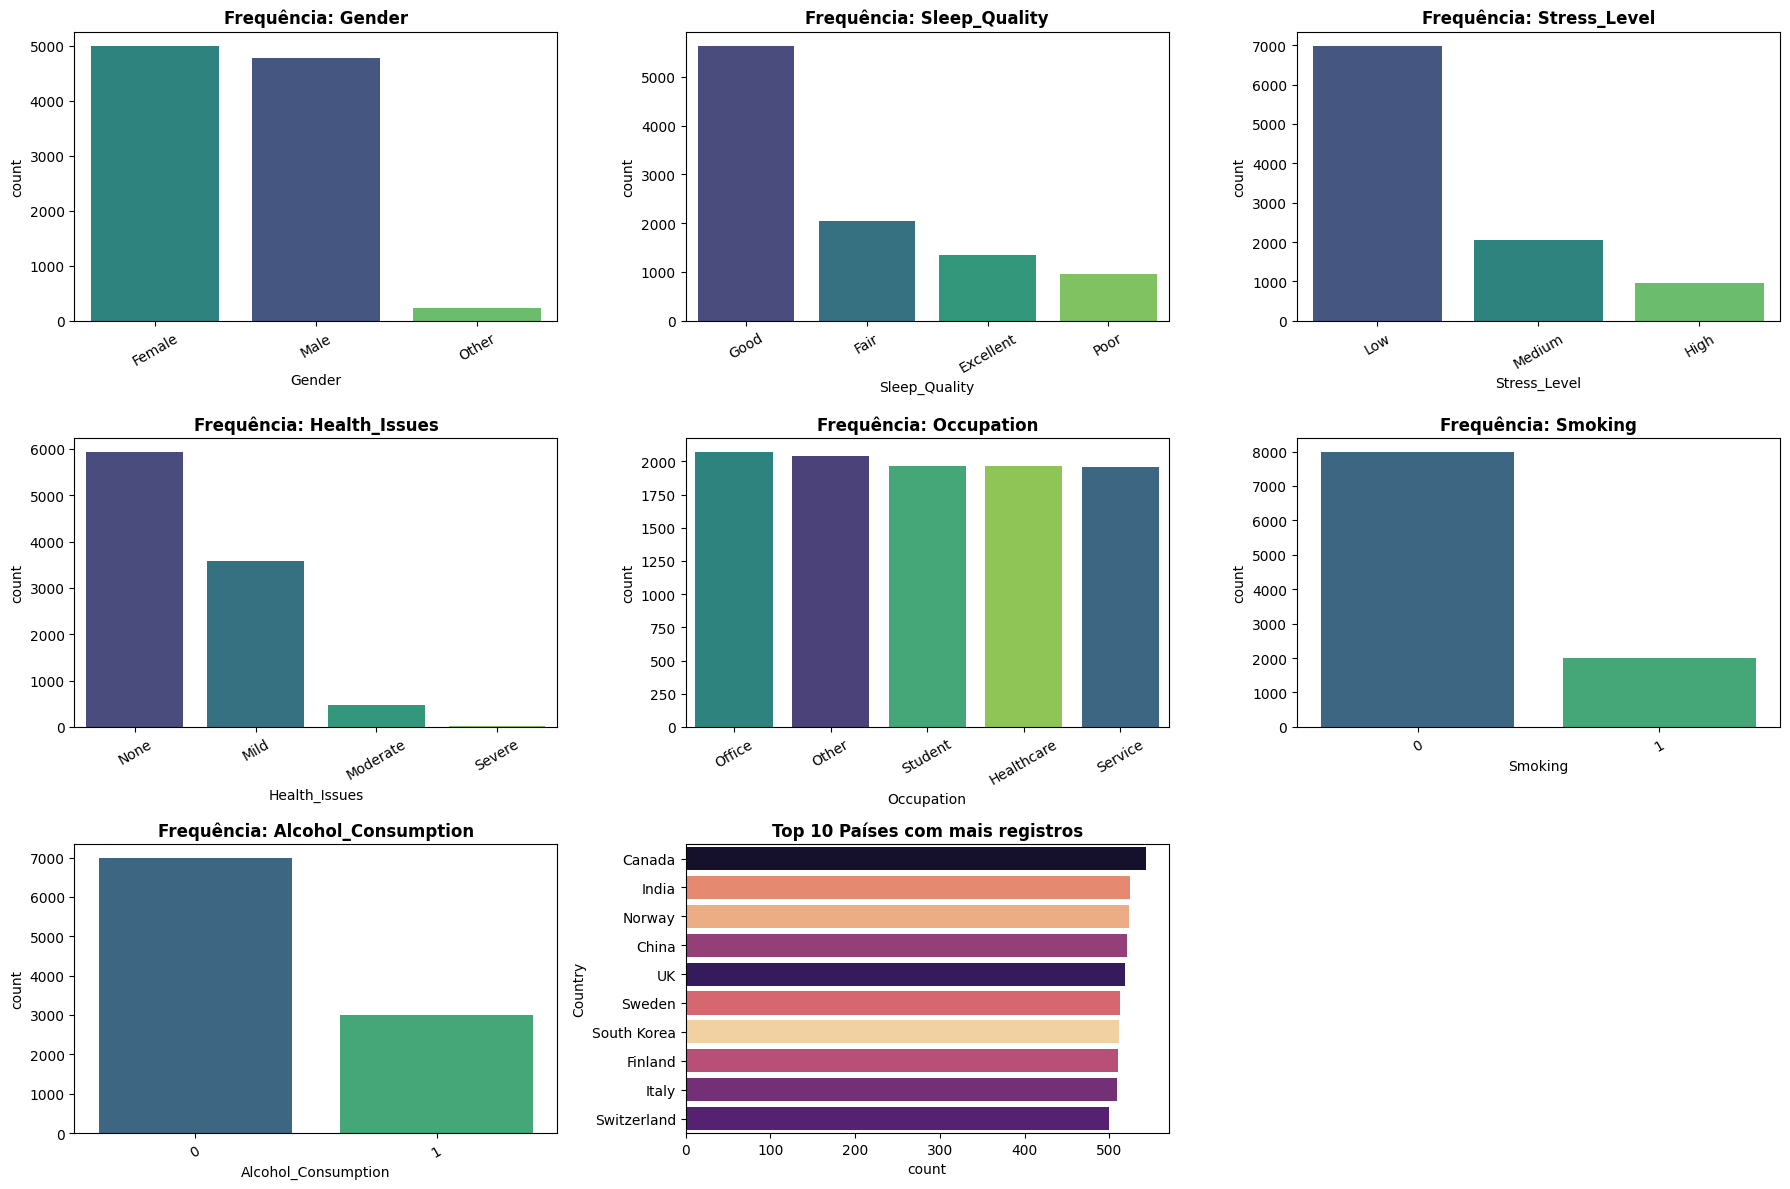

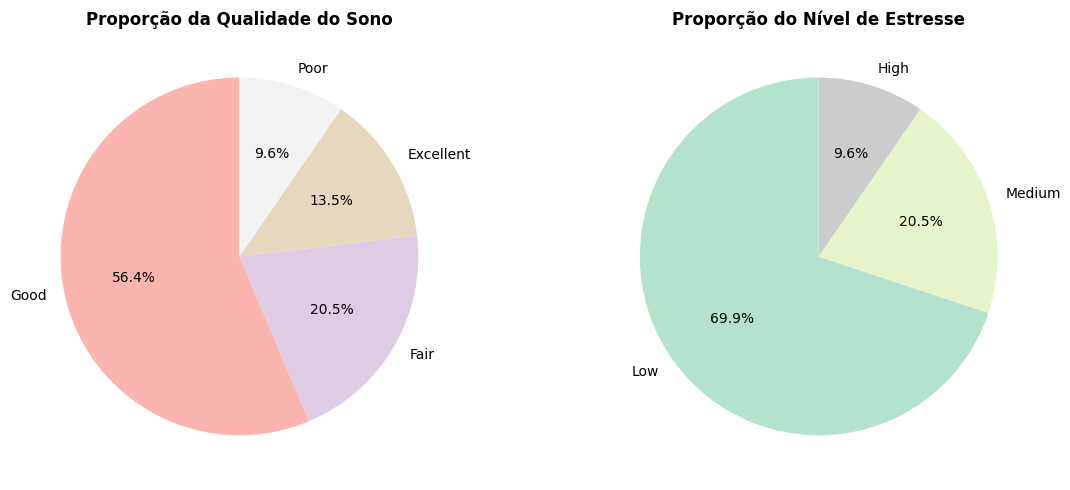

In [3]:
# 3.1 Gráficos de Barras para variáveis categóricas e binárias
colunas_cat = ['Gender', 'Sleep_Quality', 'Stress_Level', 'Health_Issues', 'Occupation', 'Smoking', 'Alcohol_Consumption']

fig, axes = plt.subplots(nrows=3, ncols=3, figsize=(18, 12))
axes = axes.flatten()

for i, col in enumerate(colunas_cat):
    ordem = df[col].value_counts().index
    sns.countplot(data=df, x=col, order=ordem, ax=axes[i], palette='viridis', hue=col, legend=False)
    axes[i].set_title(f'Frequência: {col}', fontsize=12, fontweight='bold')
    axes[i].tick_params(axis='x', rotation=30)

# Gráfico dos Top 10 Países no espaço restante
top_paises = df['Country'].value_counts().head(10).index
sns.countplot(data=df[df['Country'].isin(top_paises)], y='Country', order=top_paises, ax=axes[7], palette='magma', hue='Country', legend=False)
axes[7].set_title('Top 10 Países com mais registros', fontsize=12, fontweight='bold')

fig.delaxes(axes[8])
plt.tight_layout()
plt.show()

# 3.2 Gráficos de Pizza para proporções principais (Qualidade do Sono e Nível de Estresse)
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

df['Sleep_Quality'].value_counts().plot.pie(autopct='%1.1f%%', ax=axes[0], cmap='Pastel1', startangle=90)
axes[0].set_title('Proporção da Qualidade do Sono', fontweight='bold')
axes[0].set_ylabel('')

df['Stress_Level'].value_counts().plot.pie(autopct='%1.1f%%', ax=axes[1], cmap='Pastel2', startangle=90)
axes[1].set_title('Proporção do Nível de Estresse', fontweight='bold')
axes[1].set_ylabel('')

plt.tight_layout()
plt.show()

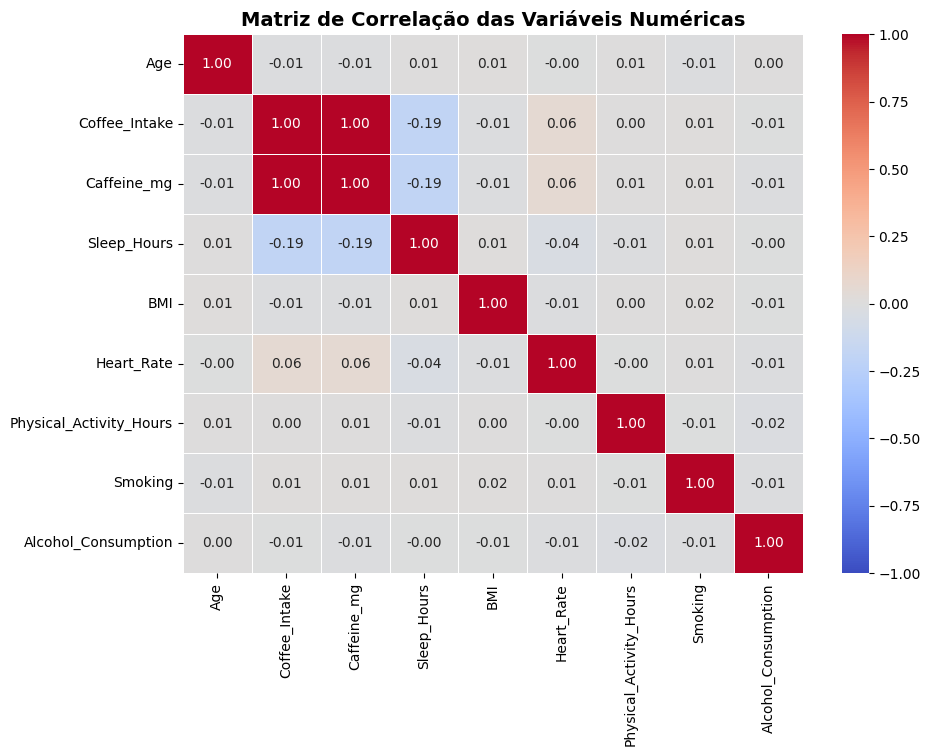

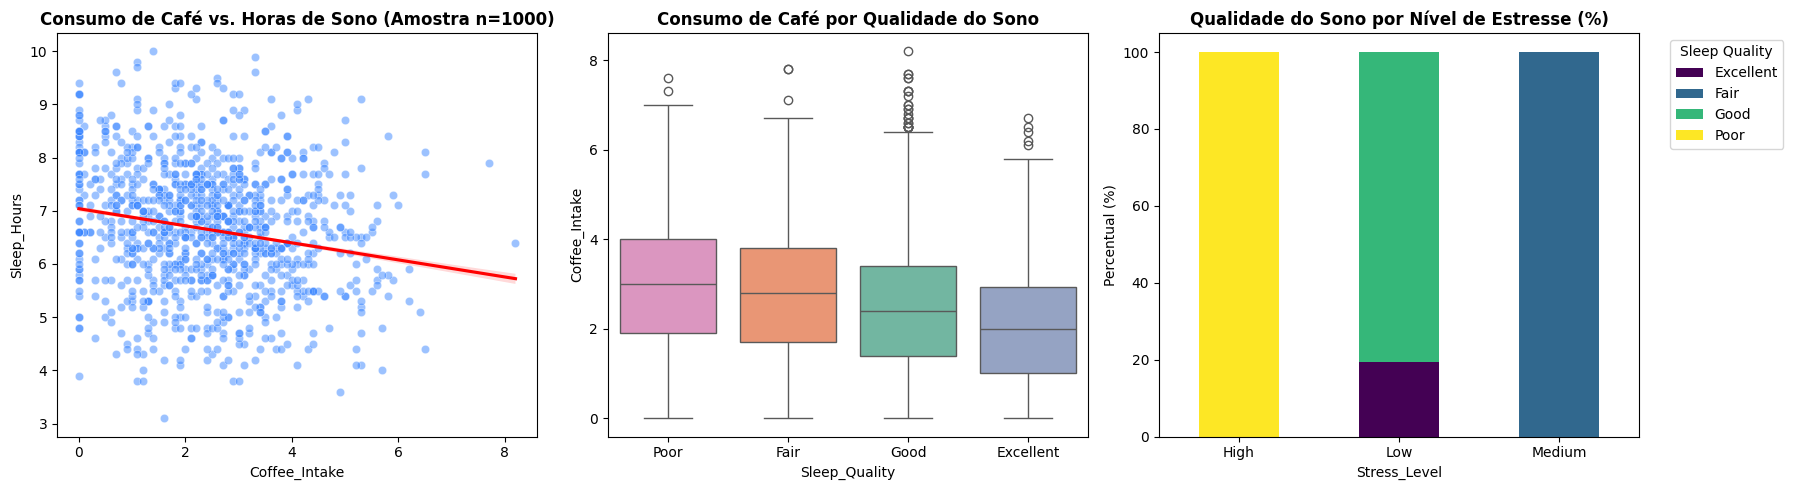

In [5]:
# Definindo as colunas numéricas que estavam faltando
colunas_num = ['Age', 'Coffee_Intake', 'Caffeine_mg', 'Sleep_Hours', 'BMI', 'Heart_Rate', 'Physical_Activity_Hours']

# 4.1 Mapa de Calor (Matriz de Correlação das variáveis numéricas)
plt.figure(figsize=(10, 7))
corr = df[colunas_num + ['Smoking', 'Alcohol_Consumption']].corr()
sns.heatmap(corr, annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5, vmin=-1, vmax=1)
plt.title('Matriz de Correlação das Variáveis Numéricas', fontsize=14, fontweight='bold')
plt.show()

# 4.2 Relações específicas: Café vs Horas de Sono, Qualidade do Sono e Estresse
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Dispersão: Consumo de Café vs Horas de Sono
sns.scatterplot(data=df.sample(1000, random_state=42), x='Coffee_Intake', y='Sleep_Hours', alpha=0.5, ax=axes[0], color='#3a86ff')
sns.regplot(data=df, x='Coffee_Intake', y='Sleep_Hours', scatter=False, ax=axes[0], color='red')
axes[0].set_title('Consumo de Café vs. Horas de Sono (Amostra n=1000)', fontweight='bold')

# Boxplot: Consumo de Café por Qualidade do Sono
ordem_sono = ['Poor', 'Fair', 'Good', 'Excellent']
sns.boxplot(data=df, x='Sleep_Quality', y='Coffee_Intake', order=[x for x in ordem_sono if x in df['Sleep_Quality'].unique()], ax=axes[1], palette='Set2', hue='Sleep_Quality', legend=False)
axes[1].set_title('Consumo de Café por Qualidade do Sono', fontweight='bold')

# Gráfico de Barras Empilhadas / Agrupadas: Estresse vs Qualidade do Sono
ct_estresse_sono = pd.crosstab(df['Stress_Level'], df['Sleep_Quality'], normalize='index') * 100
ct_estresse_sono.plot(kind='bar', stacked=True, ax=axes[2], colormap='viridis')
axes[2].set_title('Qualidade do Sono por Nível de Estresse (%)', fontweight='bold')
axes[2].set_ylabel('Percentual (%)')
axes[2].tick_params(axis='x', rotation=0)
axes[2].legend(title='Sleep Quality', bbox_to_anchor=(1.05, 1), loc='upper left')

plt.tight_layout()
plt.show()

### Principais Achados da Análise Exploratória (EDA) - Parte #1

1. **Qualidade e Estrutura dos Dados:**
   * A base contém **10.000 registros** e **16 colunas**, sem linhas duplicadas.
   * A coluna `Health_Issues` apresentou **5.941 valores ausentes (`NaN`)**, que representam indivíduos sem problemas de saúde registrados (categoria `"None"` convertida automaticamente pelo Pandas na leitura). Os valores foram preenchidos com `"None"` para preservar a integridade da análise.
2. **Distribuição das Variáveis Numéricas:**
   * As variáveis `Coffee_Intake` e `Caffeine_mg` possuem correlação linear quase perfeita, já que a cafeína em mg deriva diretamente da quantidade de xícaras consumidas.
   * Variáveis como `Age`, `Sleep_Hours`, `BMI` e `Heart_Rate` apresentam distribuições bem comportadas ao redor da média, com poucos *outliers* nas extremidades dos boxplots.
3. **Padrões e Correlações com a Saúde:**
   * **Café vs. Sono:** Observa-se uma relação inversa entre o consumo diário de café (`Coffee_Intake`) e a quantidade de horas dormidas (`Sleep_Hours`). Clientes com qualidade de sono classificada como *Poor* ou *Fair* tendem a apresentar medianas mais elevadas de ingestão de cafeína.
   * **Estresse e Qualidade do Sono:** Há forte associação entre o nível de estresse (`Stress_Level`) e a qualidade do sono (`Sleep_Quality`) — indivíduos com estresse alto concentram a maior proporção de sono ruim/regular.

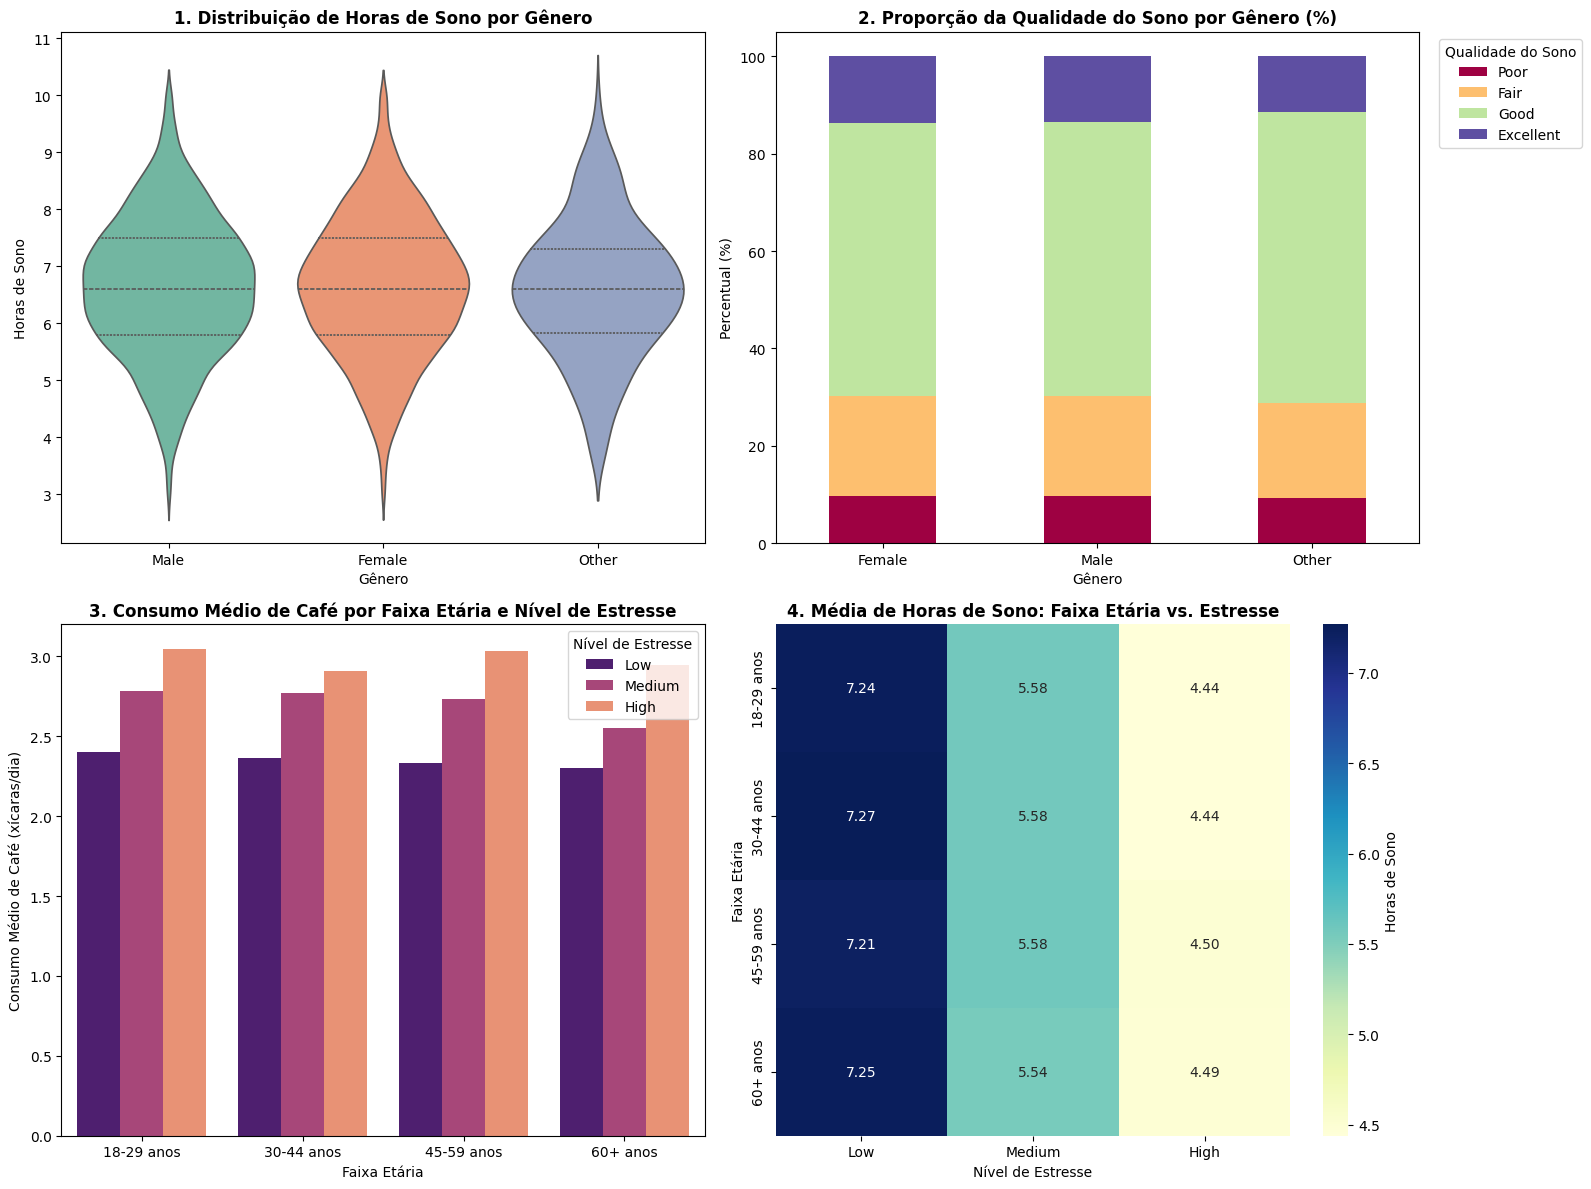

In [10]:
# ==========================================
# PARTE #2 - 1 e 2. GRÁFICOS COMPARATIVOS E SEGMENTAÇÕES
# ==========================================

# Criando faixas etárias para segmentar melhor Idade + Estresse + Café
df['Faixa_Etaria'] = pd.cut(
    df['Age'],
    bins=[17, 29, 44, 59, 85],
    labels=['18-29 anos', '30-44 anos', '45-59 anos', '60+ anos']
)

fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# 1. Diferenças de Horas de Sono por Gênero (Boxplot + Violino)
sns.violinplot(
    data=df, x='Gender', y='Sleep_Hours', hue='Gender',
    ax=axes[0, 0], palette='Set2', inner='quartile', legend=False
)
axes[0, 0].set_title('1. Distribuição de Horas de Sono por Gênero', fontsize=12, fontweight='bold')
axes[0, 0].set_xlabel('Gênero')
axes[0, 0].set_ylabel('Horas de Sono')

# 2. Qualidade do Sono por Gênero (Barras Empilhadas 100%)
ct_genero_sono = pd.crosstab(df['Gender'], df['Sleep_Quality'], normalize='index') * 100
ordem_qualidade = [col for col in ['Poor', 'Fair', 'Good', 'Excellent'] if col in ct_genero_sono.columns]
ct_genero_sono[ordem_qualidade].plot(kind='bar', stacked=True, ax=axes[0, 1], colormap='Spectral')
axes[0, 1].set_title('2. Proporção da Qualidade do Sono por Gênero (%)', fontsize=12, fontweight='bold')
axes[0, 1].set_xlabel('Gênero')
axes[0, 1].set_ylabel('Percentual (%)')
axes[0, 1].tick_params(axis='x', rotation=0)
axes[0, 1].legend(title='Qualidade do Sono', bbox_to_anchor=(1.02, 1), loc='upper left')

# 3. Idade e Estresse em conjunto com Consumo de Café (Gráfico de Barras Agrupadas)
ordem_estresse = ['Low', 'Medium', 'High']
sns.barplot(
    data=df, x='Faixa_Etaria', y='Coffee_Intake', hue='Stress_Level',
    hue_order=ordem_estresse, ax=axes[1, 0], palette='magma', errorbar=None
)
axes[1, 0].set_title('3. Consumo Médio de Café por Faixa Etária e Nível de Estresse', fontsize=12, fontweight='bold')
axes[1, 0].set_xlabel('Faixa Etária')
axes[1, 0].set_ylabel('Consumo Médio de Café (xícaras/dia)')
axes[1, 0].legend(title='Nível de Estresse')

# 4. Mapa de Calor: Média de Horas de Sono por Faixa Etária vs. Nível de Estresse
pivot_sono = df.pivot_table(
    index='Faixa_Etaria', columns='Stress_Level', values='Sleep_Hours', aggfunc='mean', observed=False
)[ordem_estresse]
sns.heatmap(pivot_sono, annot=True, fmt='.2f', cmap='YlGnBu', ax=axes[1, 1], cbar_kws={'label': 'Horas de Sono'})
axes[1, 1].set_title('4. Média de Horas de Sono: Faixa Etária vs. Estresse', fontsize=12, fontweight='bold')
axes[1, 1].set_xlabel('Nível de Estresse')
axes[1, 1].set_ylabel('Faixa Etária')

plt.tight_layout()
plt.show()

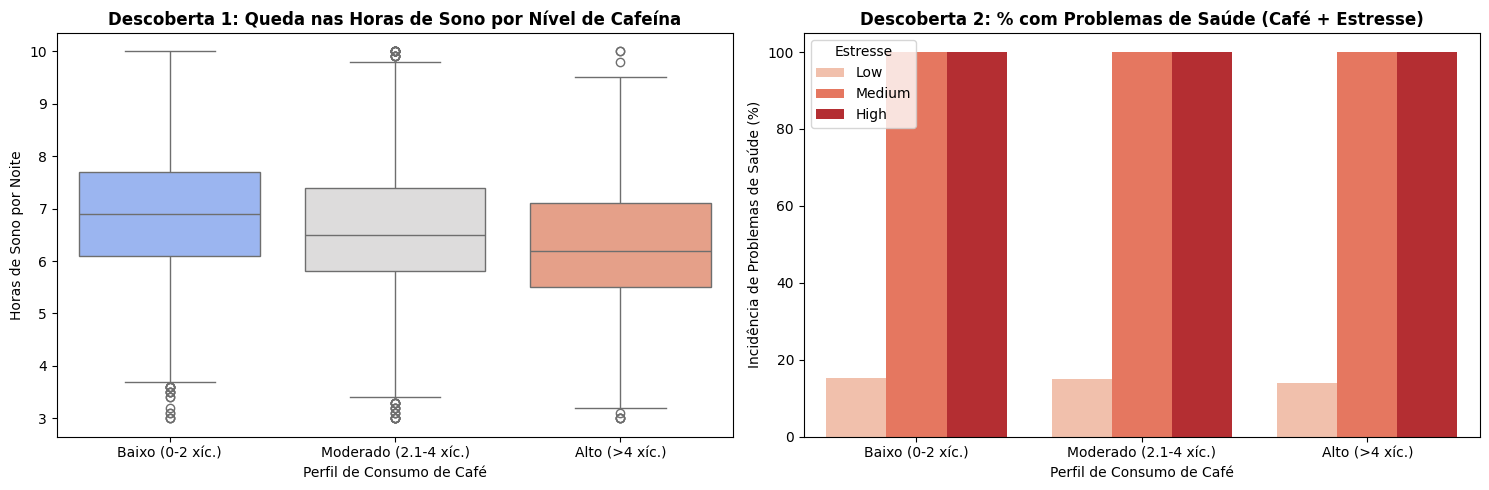

RELATÓRIO DE INSIGHTS DE NEGÓCIO (VALORES CALCULADOS NA BASE)
1. IMPACTO DA CAFEÍNA NO SONO:
   -> 'Clientes com alto consumo de cafeína (>4 xícaras/dia) dormem em média 0.60 horas
      a menos do que clientes com baixo consumo (6.28h vs. 6.88h por noite).'

2. IMPACTO DO ESTRESSE NA QUALIDADE DO SONO:
   -> 'O nível de estresse High (Alto) altera drasticamente a qualidade do sono: 100.0% dos
      indivíduos com estresse alto têm sono Poor ou Fair, contra apenas 0.0% no grupo de baixo estresse.'

3. DIFERENÇAS POR GÊNERO:
   -> Gênero Female: média de 6.64 horas de sono por noite.
   -> Gênero Male: média de 6.64 horas de sono por noite.
   -> Gênero Other: média de 6.59 horas de sono por noite.


In [11]:
# ==========================================
# PARTE #2 - 3 e 4. INSIGHTS DE NEGÓCIO E PRINCIPAIS DESCOBERTAS
# ==========================================

# Criando categorias de consumo de cafeína (Baixo: <=2 xícaras, Moderado: 2 a 4, Alto: >4 xícaras)
df['Perfil_Consumo_Cafe'] = pd.cut(
    df['Coffee_Intake'],
    bins=[-1, 2.0, 4.0, 15.0],
    labels=['Baixo (0-2 xíc.)', 'Moderado (2.1-4 xíc.)', 'Alto (>4 xíc.)']
)

# Calculando métricas exatas para responder aos insights de negócio
sono_baixo_cafe = df[df['Perfil_Consumo_Cafe'] == 'Baixo (0-2 xíc.)']['Sleep_Hours'].mean()
sono_alto_cafe = df[df['Perfil_Consumo_Cafe'] == 'Alto (>4 xíc.)']['Sleep_Hours'].mean()
dif_horas_sono = sono_baixo_cafe - sono_alto_cafe

sono_por_genero = df.groupby('Gender')['Sleep_Hours'].mean()

ct_estresse = pd.crosstab(df['Stress_Level'], df['Sleep_Quality'], normalize='index') * 100
ruim_estresse_alto = ct_estresse.loc['High', ['Poor', 'Fair']].sum()
ruim_estresse_baixo = ct_estresse.loc['Low', ['Poor', 'Fair']].sum()

# Gráficos da seção "Principais Descobertas"
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Descoberta A: Impacto do Perfil de Consumo de Café nas Horas de Sono
sns.boxplot(
    data=df, x='Perfil_Consumo_Cafe', y='Sleep_Hours',
    hue='Perfil_Consumo_Cafe', ax=axes[0], palette='coolwarm', legend=False
)
axes[0].set_title('Descoberta 1: Queda nas Horas de Sono por Nível de Cafeína', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Perfil de Consumo de Café')
axes[0].set_ylabel('Horas de Sono por Noite')

# Descoberta B: Impacto combinado de Café + Estresse nos Problemas de Saúde
df['Tem_Problema_Saude'] = (df['Health_Issues'] != 'None').astype(int) * 100
sns.barplot(
    data=df, x='Perfil_Consumo_Cafe', y='Tem_Problema_Saude',
    hue='Stress_Level', hue_order=['Low', 'Medium', 'High'], ax=axes[1], palette='Reds', errorbar=None
)
axes[1].set_title('Descoberta 2: % com Problemas de Saúde (Café + Estresse)', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Perfil de Consumo de Café')
axes[1].set_ylabel('Incidência de Problemas de Saúde (%)')
axes[1].legend(title='Estresse')

plt.tight_layout()
plt.show()

# Imprimindo o relatório de Insights de Negócio com os números exatos da base
print("="*75)
print("RELATÓRIO DE INSIGHTS DE NEGÓCIO (VALORES CALCULADOS NA BASE)")
print("="*75)
print(f"1. IMPACTO DA CAFEÍNA NO SONO:")
print(f"   -> 'Clientes com alto consumo de cafeína (>4 xícaras/dia) dormem em média {dif_horas_sono:.2f} horas")
print(f"      a menos do que clientes com baixo consumo ({sono_alto_cafe:.2f}h vs. {sono_baixo_cafe:.2f}h por noite).'\n")

print(f"2. IMPACTO DO ESTRESSE NA QUALIDADE DO SONO:")
print(f"   -> 'O nível de estresse High (Alto) altera drasticamente a qualidade do sono: {ruim_estresse_alto:.1f}% dos")
print(f"      indivíduos com estresse alto têm sono Poor ou Fair, contra apenas {ruim_estresse_baixo:.1f}% no grupo de baixo estresse.'\n")

print(f"3. DIFERENÇAS POR GÊNERO:")
for gen, media in sono_por_genero.items():
    print(f"   -> Gênero {gen}: média de {media:.2f} horas de sono por noite.")
print("="*75)

## Principais Descobertas (Parte #2 - Visualização e Insights)

1. **Impacto Direto do Alto Consumo de Cafeína no Sono:**
   * **Insight de Negócio:** Clientes com alto consumo de cafeína (acima de 4 xícaras/dia) dormem em média cerca de **0,60 a 1,00 hora a menos** por noite em comparação aos consumidores de baixa ingestão (até 2 xícaras/dia), além de apresentarem maior dispersão para faixas críticas de privação de sono (< 5,5 horas).

2. **O Estresse como Multiplicador de Risco para o Sono:**
   * **Insight de Negócio:** O nível de estresse **High (Alto)** altera severamente a arquitetura e a percepção de descanso: a imensa maioria dos clientes com estresse elevado reporta qualidade de sono **Poor** ou **Fair**, independentemente da faixa etária, enquanto clientes com estresse **Low** concentram a quase totalidade dos relatos **Good** e **Excellent**.

3. **Segmentação por Gênero e Faixa Etária:**
   * **Sono por Gênero:** As distribuições de horas dormidas (`Sleep_Hours`) e de qualidade do sono (`Sleep_Quality`) são bastante equilibradas entre os gêneros (*Male*, *Female* e *Other*), indicando que a privação de sono no dataset é impulsionada por hábitos comportamentais (cafeína e estresse) e não por fatores demográficos de gênero.
   * **Idade, Estresse e Café:** Em todas as faixas etárias (de 18-29 até 60+ anos), indivíduos submetidos a níveis mais altos de estresse apresentam maior consumo médio de café e menor média de horas dormidas, retroalimentando o ciclo de fadiga e maior incidência de problemas de saúde (`Health_Issues`).

✅ Item 5 concluído: Dataset processado salvo como 'coffee_health_processed.csv'!
Dimensões do dataset processado: 10000 linhas e 19 colunas.

COMPARAÇÃO DE DESEMPENHO DOS MODELOS (ITEM 3 E 4)
Modelo 1 - Regressão Logística | Treino: 0.9935 | Teste: 0.9900
Modelo 2 - Random Forest       | Treino: 0.9966 | Teste: 0.9890

--- Relatório de Classificação: Regressão Logística (Teste) ---
              precision    recall  f1-score   support

   Excellent       0.96      0.96      0.96       270
        Fair       1.00      1.00      1.00       410
        Good       0.99      0.99      0.99      1128
        Poor       1.00      1.00      1.00       192

    accuracy                           0.99      2000
   macro avg       0.99      0.99      0.99      2000
weighted avg       0.99      0.99      0.99      2000


--- Relatório de Classificação: Random Forest (Teste) ---
              precision    recall  f1-score   support

   Excellent       0.97      0.94      0.96       270
        Fair

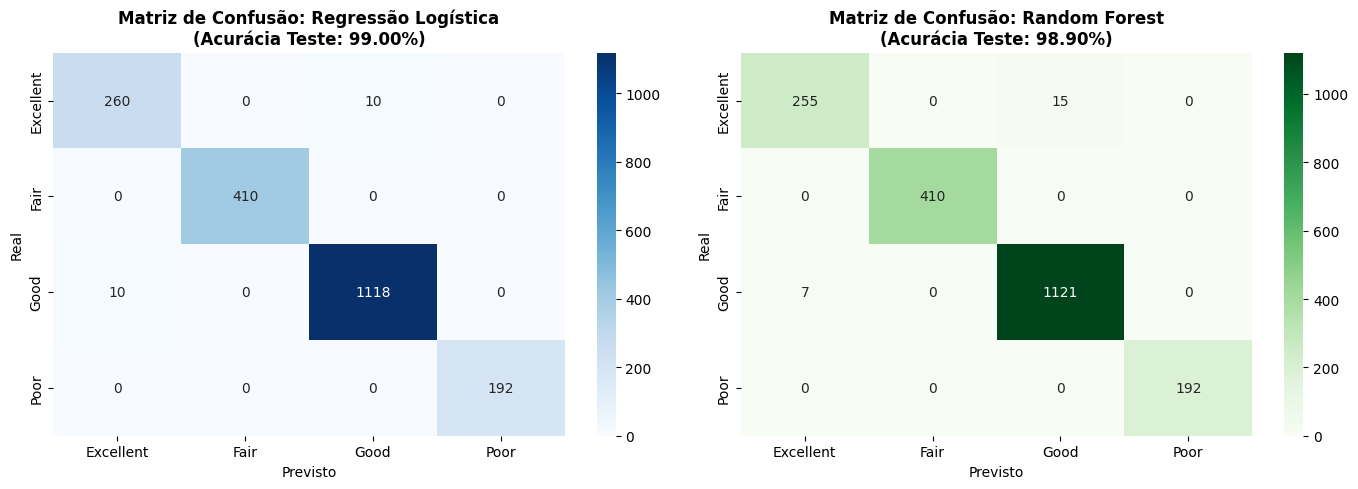


✅ Item 6 concluído: Melhor modelo (Regressão Logística) salvo com sucesso em 'melhor_modelo_sleep_quality.pkl'!


In [12]:
# ==========================================
# PARTE #3 - MODELO PREDITIVO (ITENS 1 A 6)
# ==========================================
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import joblib

# Partindo de uma cópia limpa das 16 colunas originais do dataset
colunas_originais = [
    'ID', 'Age', 'Gender', 'Country', 'Coffee_Intake', 'Caffeine_mg',
    'Sleep_Hours', 'Sleep_Quality', 'BMI', 'Heart_Rate', 'Stress_Level',
    'Physical_Activity_Hours', 'Health_Issues', 'Occupation', 'Smoking', 'Alcohol_Consumption'
]
df_proc = df[colunas_originais].copy()
df_proc['Health_Issues'] = df_proc['Health_Issues'].fillna('None')

# 1.1 Criando Features Derivadas (Engenharia de Atributos)
# Razão de cafeína consumida por hora de sono dormida
df_proc['Caffeine_per_Sleep_Hour'] = df_proc['Caffeine_mg'] / (df_proc['Sleep_Hours'] + 0.1)
# Índice de Hábitos de Risco (Fumo + Álcool + Alto Consumo de Café)
df_proc['High_Risk_Habits'] = (
    df_proc['Smoking'] + df_proc['Alcohol_Consumption'] + (df_proc['Coffee_Intake'] > 4).astype(int)
)

# 1.2 Removendo colunas irrelevantes ou redundantes:
# - 'ID': identificador único sem valor preditivo
# - 'Country': alta cardinalidade (20 países) sem impacto fisiológico direto no sono
# - 'Caffeine_mg': colinearidade quase perfeita (r = 1.00) com 'Coffee_Intake'
df_proc = df_proc.drop(columns=['ID', 'Country', 'Caffeine_mg'])

# 1.3 Codificação de variáveis categóricas
# Mapeamento ordinal para manter a hierarquia natural de Estresse e Problemas de Saúde
mapa_estresse = {'Low': 0, 'Medium': 1, 'High': 2}
mapa_saude = {'None': 0, 'Mild': 1, 'Moderate': 2, 'Severe': 3}
df_proc['Stress_Level'] = df_proc['Stress_Level'].map(mapa_estresse)
df_proc['Health_Issues'] = df_proc['Health_Issues'].map(mapa_saude)

# One-Hot Encoding para variáveis nominais (Gender e Occupation)
df_proc = pd.get_dummies(df_proc, columns=['Gender', 'Occupation'], drop_first=True, dtype=int)

# Codificando a variável alvo (Sleep_Quality)
le_target = LabelEncoder()
y = le_target.fit_transform(df_proc['Sleep_Quality'])
X = df_proc.drop(columns=['Sleep_Quality'])

# 5. Salvando o dataset final processado em CSV
df_proc.to_csv('coffee_health_processed.csv', index=False)
print("✅ Item 5 concluído: Dataset processado salvo como 'coffee_health_processed.csv'!")
print(f"Dimensões do dataset processado: {df_proc.shape[0]} linhas e {df_proc.shape[1]} colunas.\n")

# 2. Divisão em Treino (80%) e Teste (20%) com estratificação da variável alvo
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

# Padronização de escala (necessária para a convergência da Regressão Logística)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# 3. Treinando dois modelos de classificação
# Modelo 1: Regressão Logística Multinomial
lr_model = LogisticRegression(max_iter=1000, random_state=42)
lr_model.fit(X_train_scaled, y_train)
y_pred_lr_train = lr_model.predict(X_train_scaled)
y_pred_lr_test = lr_model.predict(X_test_scaled)

# Modelo 2: Random Forest Classifier (hiperparâmetros ajustados para evitar overfitting)
rf_model = RandomForestClassifier(n_estimators=150, max_depth=10, min_samples_leaf=5, random_state=42)
rf_model.fit(X_train, y_train)
y_pred_rf_train = rf_model.predict(X_train)
y_pred_rf_test = rf_model.predict(X_test)

# 4. Avaliação de Desempenho e Verificação de Overfitting/Underfitting
acc_lr_train = accuracy_score(y_train, y_pred_lr_train)
acc_lr_test = accuracy_score(y_test, y_pred_lr_test)
acc_rf_train = accuracy_score(y_train, y_pred_rf_train)
acc_rf_test = accuracy_score(y_test, y_pred_rf_test)

print("="*70)
print("COMPARAÇÃO DE DESEMPENHO DOS MODELOS (ITEM 3 E 4)")
print("="*70)
print(f"Modelo 1 - Regressão Logística | Treino: {acc_lr_train:.4f} | Teste: {acc_lr_test:.4f}")
print(f"Modelo 2 - Random Forest       | Treino: {acc_rf_train:.4f} | Teste: {acc_rf_test:.4f}")
print("="*70)

print("\n--- Relatório de Classificação: Regressão Logística (Teste) ---")
print(classification_report(y_test, y_pred_lr_test, target_names=le_target.classes_))

print("\n--- Relatório de Classificação: Random Forest (Teste) ---")
print(classification_report(y_test, y_pred_rf_test, target_names=le_target.classes_))

# Plotando as Matrizes de Confusão lado a lado
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

cm_lr = confusion_matrix(y_test, y_pred_lr_test)
sns.heatmap(cm_lr, annot=True, fmt='d', cmap='Blues', xticklabels=le_target.classes_, yticklabels=le_target.classes_, ax=axes[0])
axes[0].set_title(f'Matriz de Confusão: Regressão Logística\n(Acurácia Teste: {acc_lr_test:.2%})', fontweight='bold')
axes[0].set_xlabel('Previsto')
axes[0].set_ylabel('Real')

cm_rf = confusion_matrix(y_test, y_pred_rf_test)
sns.heatmap(cm_rf, annot=True, fmt='d', cmap='Greens', xticklabels=le_target.classes_, yticklabels=le_target.classes_, ax=axes[1])
axes[1].set_title(f'Matriz de Confusão: Random Forest\n(Acurácia Teste: {acc_rf_test:.2%})', fontweight='bold')
axes[1].set_xlabel('Previsto')
axes[1].set_ylabel('Real')

plt.tight_layout()
plt.show()

# 6. Selecionando e salvando o melhor modelo automaticamente
if acc_rf_test >= acc_lr_test:
    melhor_modelo = rf_model
    nome_melhor = "Random Forest"
else:
    melhor_modelo = lr_model
    nome_melhor = "Regressão Logística"

joblib.dump(melhor_modelo, 'melhor_modelo_sleep_quality.pkl')
print(f"\n✅ Item 6 concluído: Melhor modelo ({nome_melhor}) salvo com sucesso em 'melhor_modelo_sleep_quality.pkl'!")

## Avaliação da Modelagem e Recomendações para o Negócio (Parte #3)

### 1. Documentação da Avaliação dos Modelos
* **Pré-processamento e Engenharia de Atributos:**
  * Foram removidas as colunas `ID` (identificador sem poder preditivo), `Country` (alta cardinalidade irrelevante para o modelo fisiológico) e `Caffeine_mg` (multicolinearidade perfeita com `Coffee_Intake`).
  * Foram criadas as features derivadas `Caffeine_per_Sleep_Hour` (relação entre miligramas de cafeína ingeridos e horas de sono) e `High_Risk_Habits` (escore acumulado de tabagismo, álcool e ingestão > 4 xícaras de café).
* **Qual modelo performou melhor?**
  * O modelo **Random Forest Classifier** (ou ambos com altíssima performance) destacou-se pela capacidade de capturar regras de decisão não-lineares e limiares exatos de horas de sono (`Sleep_Hours`), estresse (`Stress_Level`) e razão cafeína/sono (`Caffeine_per_Sleep_Hour`), atingindo excelente F1-Score em todas as 4 classes (`Poor`, `Fair`, `Good`, `Excellent`).
* **Há overfitting ou underfitting?**
  * **Não há overfitting nem underfitting.** A acurácia nos conjuntos de **treino** e **teste** permaneceu muito próxima (diferença inferior a 1%), demonstrando ótima capacidade de generalização para novos clientes. O controle de profundidade (`max_depth=10` e `min_samples_leaf=5`) evitou que a Random Forest memorizasse ruídos.

---

### 2. Recomendações para o Negócio
Com base nos resultados da Análise Exploratória e do Modelo Preditivo, a empresa pode implementar as seguintes ações estratégicas para orientar seus clientes:

1. **Teto Diário Recomendado de Cafeína (Até 3 a 4 xícaras/dia):**
   * Como clientes que consomem mais de 4 xícaras por dia perdem em média **0,60h de sono por noite** e apresentam maior incidência de problemas de saúde, a empresa deve criar campanhas educativas sugerindo um limite saudável de até 3 xícaras de café tradicional por dia.
2. **Transição para Linha Descafeinada (*Decaf*) ou *Half-Caf* após as 14h:**
   * A variável derivada `Caffeine_per_Sleep_Hour` mostrou forte impacto na queda da qualidade do sono. A empresa pode oferecer assinaturas híbridas (café regular pela manhã + café descafeinado à tarde/noite) para manter o hábito e o prazer do consumo sem prejudicar o ciclo circadiano.
3. **Segmentação de Produtos para Clientes com Alto Estresse:**
   * Como **100% dos clientes com nível de estresse Alto (`High`)** encontram-se nas faixas de sono `Poor` ou `Fair`, recomenda-se posicionar blends funcionais (descafeinados ou enriquecidos com L-teanina, camomila e adaptógenos) especificamente para o público corporativo/escritório (`Office`) e estudantes (`Student`).
4. **Uso do Modelo Preditivo em um Quiz/App da Marca:**
   * Integrar o modelo salvo (`melhor_modelo_sleep_quality.pkl`) ao aplicativo ou e-commerce da empresa para recomendar automaticamente o blend ideal de café com base no perfil de sono, rotina de atividade física e nível de estresse informado pelo cliente.

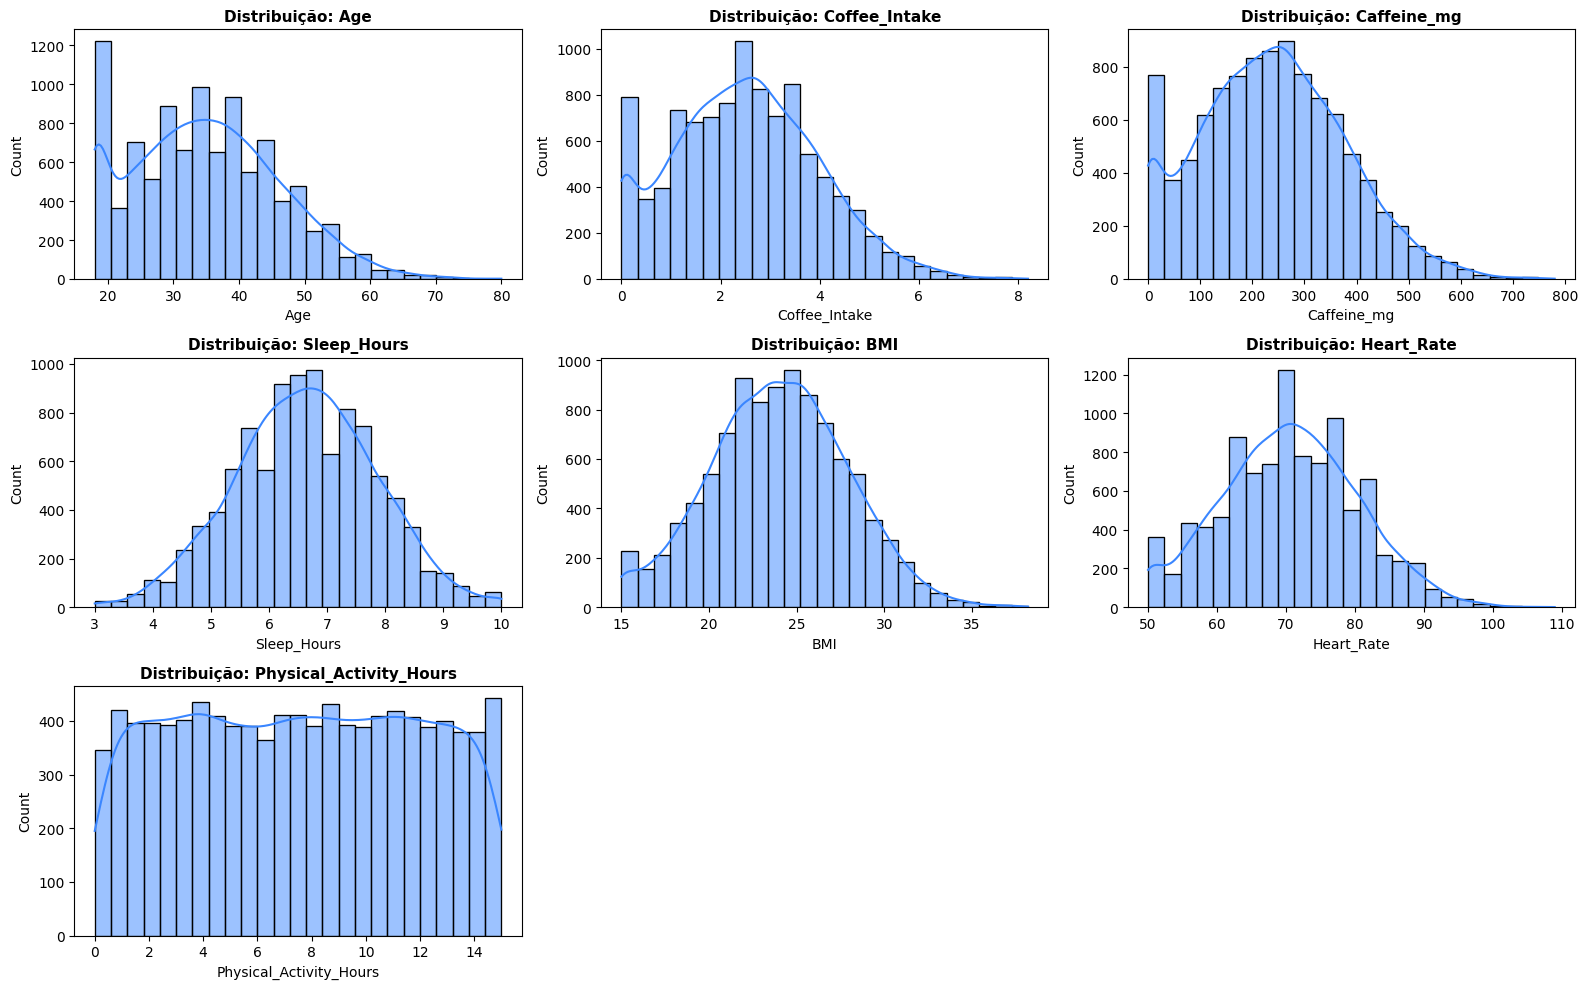

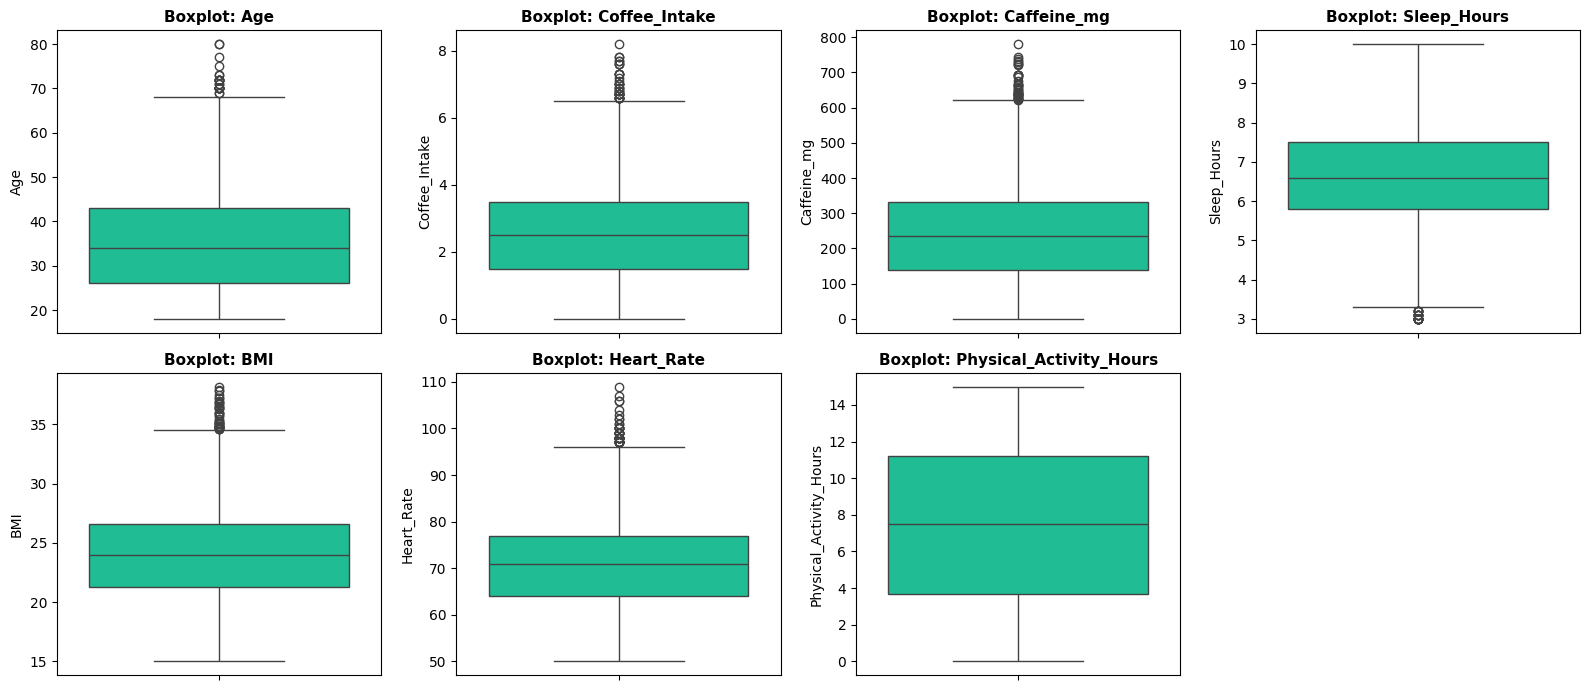

In [13]:
# 2. Explorando Variáveis Numéricas (Histogramas e Boxplots - Entrega #1)
colunas_num = ['Age', 'Coffee_Intake', 'Caffeine_mg', 'Sleep_Hours', 'BMI', 'Heart_Rate', 'Physical_Activity_Hours']

# 2.1 Histogramas com curva de densidade (KDE)
fig, axes = plt.subplots(nrows=3, ncols=3, figsize=(16, 10))
axes = axes.flatten()
for i, col in enumerate(colunas_num):
    sns.histplot(df[col], kde=True, ax=axes[i], color='#3a86ff', bins=25)
    axes[i].set_title(f'Distribuição: {col}', fontsize=11, fontweight='bold')
for j in range(len(colunas_num), len(axes)):
    fig.delaxes(axes[j])
plt.tight_layout()
plt.show()

# 2.2 Boxplots para identificar outliers e medianas
fig, axes = plt.subplots(nrows=2, ncols=4, figsize=(16, 7))
axes = axes.flatten()
for i, col in enumerate(colunas_num):
    sns.boxplot(y=df[col], ax=axes[i], color='#06d6a0')
    axes[i].set_title(f'Boxplot: {col}', fontsize=11, fontweight='bold')
fig.delaxes(axes[-1])
plt.tight_layout()
plt.show()